# Transfer Learning sobre MNIST (TensorFlow)

Se comparan dos modelos preentrenados. VGG16 y ResNet50 en dos fases:
1. **Base congelada:** solo se entrena la cabeza de clasificación.
2. **Fine-tuning:** se descongela el último bloque de la base y se sigue entrenando con una tasa de aprendizaje pequeña.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as pre_vgg
from tensorflow.keras.applications.resnet50 import preprocess_input as pre_resnet

IMG_SIZE  = 64
N_TRAIN   = 20000
EPOCHS    = 5
EPOCHS_FT = 5

## 1. Datos

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, y_train = x_train[:N_TRAIN], y_train[:N_TRAIN]

def preparar(x):
    x = tf.image.resize(x[..., None], (IMG_SIZE, IMG_SIZE))
    x = tf.image.grayscale_to_rgb(x)
    return x.numpy()

x_train = preparar(x_train)
x_test  = preparar(x_test)
print(x_train.shape, x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(20000, 64, 64, 3) (10000, 64, 64, 3)


## 2. Entrenamiento

In [3]:
# nombre: (red, preprocesado, prefijo de las capas del último bloque)
modelos = {'VGG16':    (VGG16,    pre_vgg,    'block5'),'ResNet50': (ResNet50, pre_resnet, 'conv5_'),}
resultados, historias = [], {}
mejor = {'val': 0}          # mejor modelo

def registrar(modelo, etiqueta, h, xte, nombre, preprocesar):
    # Guardamos el mejor modelo
    val_acc = h.history['val_accuracy'][-1]
    test_loss, test_acc = modelo.evaluate(xte, y_test, verbose=0)
    resultados.append({'Configuración': etiqueta, 'Val accuracy': val_acc,'Test accuracy': test_acc, 'Test loss': test_loss})
    print(f'{etiqueta}: val acc = {val_acc:.4f} | test acc = {test_acc:.4f}')
    if val_acc > mejor['val']:
        mejor.update(val=val_acc, etiqueta=etiqueta, pre=preprocesar)
        modelo.save('mejor_modelo_mnist.keras')

for nombre, (red, preprocesar, bloque) in modelos.items():
    xtr = preprocesar(x_train.copy())
    xte = preprocesar(x_test.copy())

    # base congelada
    base = red(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    modelo = keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])
    modelo.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    print(f'\n--- {nombre}: base congelada ---')
    h1 = modelo.fit(xtr, y_train, epochs=EPOCHS, batch_size=128, validation_split=0.1, verbose=2)
    registrar(modelo, f'{nombre} (congelado)', h1, xte, nombre, preprocesar)

    #fine-tuning
    base.trainable = True
    for capa in base.layers:
        capa.trainable = capa.name.startswith(bloque) and not isinstance(capa, layers.BatchNormalization)

    modelo.compile(optimizer=keras.optimizers.Adam(1e-4),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    print(f'\n--- {nombre}: fine-tuning ---')
    h2 = modelo.fit(xtr, y_train, epochs=EPOCHS_FT, batch_size=128, validation_split=0.1, verbose=2)
    registrar(modelo, f'{nombre} (fine-tuning)', h2, xte, nombre, preprocesar)
    historias[nombre] = {k: h1.history[k] + h2.history[k] for k in h1.history}

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- VGG16: base congelada ---
Epoch 1/5
141/141 - 17s - 124ms/step - accuracy: 0.7830 - loss: 0.9227 - val_accuracy: 0.9195 - val_loss: 0.2656
Epoch 2/5
141/141 - 6s - 46ms/step - accuracy: 0.9320 - loss: 0.2157 - val_accuracy: 0.9470 - val_loss: 0.1826
Epoch 3/5
141/141 - 6s - 46ms/step - accuracy: 0.9516 - loss: 0.1512 - val_accuracy: 0.9555 - val_loss: 0.1510
Epoch 4/5
141/141 - 6s - 46ms/step - accuracy: 0.9662 - loss: 0.1135 - val_accuracy: 0.9615 - val_loss: 0.1367
Epoch 5/5
141/141 - 6s - 46ms/step - accuracy: 0.9704 - loss: 0.0954 - val_accuracy: 0.9660 - val_loss: 0.1271
VGG16 (congelado): val acc = 0.9660 | test acc = 0.9558

--- VGG16: fine-tuning ---
Epoch 1/5
141/141 - 18s - 124ms/step - accuracy: 0.9633 - loss: 0.1287 - val_accuracy: 0.9805 - val_loss: 0.0711
Epoch 2/5
141/141 - 8s - 60ms/step - accuracy: 0.9878 - loss: 0.0402 - val_accuracy: 0.9885 - val_loss: 0.0437
Epoch 3/5
141/141 - 9s - 61ms/step - accuracy: 0.9919

## 3. Resultados

,Val accuracy,Test accuracy,Test loss
Configuración,,,
VGG16 (congelado),0.9660,0.9558,0.1518
VGG16 (fine-tuning),0.9875,0.9857,0.0553
ResNet50 (congelado),0.9725,0.9673,0.1093
ResNet50 (fine-tuning),0.9865,0.9848,0.0498


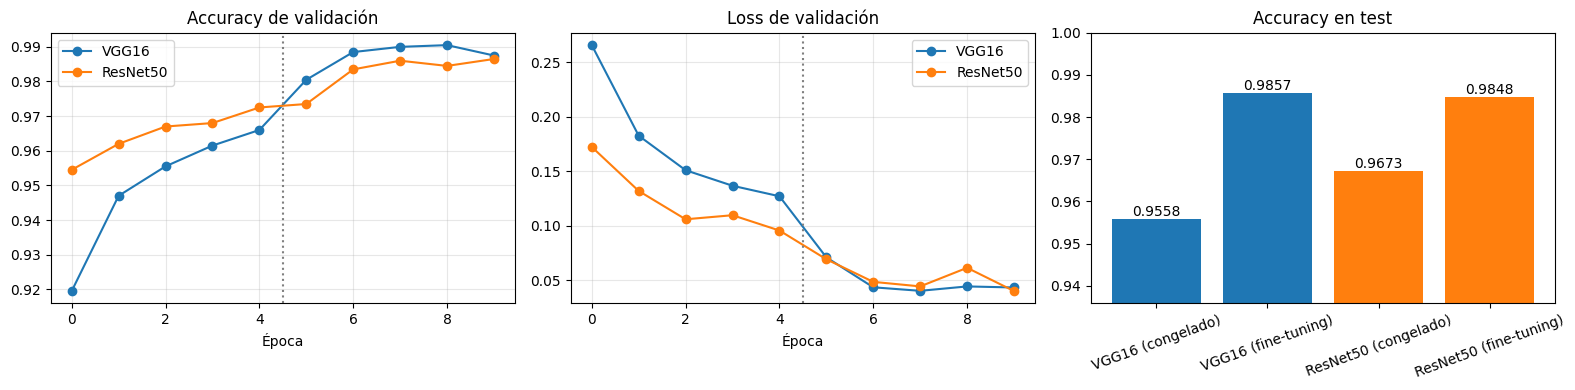

Mejor modelo: VGG16 (fine-tuning) (val accuracy = 0.9875)
Test accuracy: 0.9857


In [4]:
tabla = pd.DataFrame(resultados).set_index('Configuración')
display(tabla.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for nombre, h in historias.items():
    axes[0].plot(h['val_accuracy'], marker='o', label=nombre)
    axes[1].plot(h['val_loss'], marker='o', label=nombre)
axes[0].set_title('Accuracy de validación'); axes[1].set_title('Loss de validación')
for ax in axes[:2]:
    ax.axvline(EPOCHS - 0.5, color='gray', ls=':')       # aquí empieza el fine-tuning
    ax.set_xlabel('Época'); ax.legend(); ax.grid(alpha=.3)

axes[2].bar(tabla.index, tabla['Test accuracy'], color=['tab:blue', 'tab:blue', 'tab:orange', 'tab:orange'])
axes[2].set_title('Accuracy en test'); axes[2].tick_params(axis='x', rotation=20)
axes[2].set_ylim(tabla['Test accuracy'].min() - 0.02, 1)
for i, v in enumerate(tabla['Test accuracy']):
    axes[2].text(i, v, f'{v:.4f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

print(f"Mejor modelo: {mejor['etiqueta']} (val accuracy = {mejor['val']:.4f})")
print(f"Test accuracy: {tabla.loc[mejor['etiqueta'], 'Test accuracy']:.4f}")

## 4. Usar el modelo guardado

In [5]:
modelo_cargado = keras.models.load_model('mejor_modelo_mnist.keras')

x_nuevo = mejor['pre'](x_test[:10].copy())      # mismo preprocesado que en el entrenamiento
pred = modelo_cargado.predict(x_nuevo, verbose=0).argmax(axis=1)
print('Reales:   ', y_test[:10])
print('Predichas:', pred)

Reales:    [7 2 1 0 4 1 4 9 5 9]
Predichas: [7 2 1 0 4 1 4 9 5 9]


## 5. Conclusión

Observamos como la mejor configuración es: VGG16 con fine-tuning, con 98.75% en validación y 98.57% en test.
ResNet50 tiene practicamente los mismos resultados,con un menor numero de errores aunque con un mayor tiempo de ejecución.